### Practice 6 - Notebook 2

# Applications of Clustering and PCA — Exercise 6

## Preprocessing Pipeline: Trying `PCA(n_components=0.80)` and `PCA(n_components=0.99)`

In this exercise, we build a scikit-learn Pipeline on the Digits dataset incorporating feature scaling (`StandardScaler`), dimensionality reduction (`PCA` with cumulative variance thresholds of 80% and 99%), and a classifier (`LogisticRegression`).

**Question:** In the digits Pipeline, try `PCA(n_components=0.80)` and `PCA(n_components=0.99)`. How do the number of features and the accuracy change?

## Cell 1 — Import Required Libraries

Import NumPy, Pandas, Matplotlib, and scikit-learn tools (`load_digits`, `StandardScaler`, `PCA`, `LogisticRegression`, `Pipeline`, `train_test_split`).

In [27]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_digits
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split

## Cell 2 — Load and Split the Digits Dataset

Load the 64-feature Digits dataset and split it into training (80%) and testing (20%) sets.

In [28]:
digits = load_digits()
X, y = digits.data, digits.target

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("Training set shape:", X_train.shape)
print("Testing set shape: ", X_test.shape)

Training set shape: (1437, 64)
Testing set shape:  (360, 64)


## Cell 3 — Build and Evaluate Pipelines with PCA (80%, 99%) and No PCA

We construct scikit-learn Pipelines combining standardization, PCA (retaining 80% or 99% variance), and Logistic Regression, and compare them against the raw feature baseline.

In [29]:
results = []
configs = [
    ("PCA (n_components=0.80)", 0.80),
    ("PCA (n_components=0.99)", 0.99),
    ("No PCA (Raw 64 features)", None)
]

for name, n_comp in configs:
    if n_comp is not None:
        pipe = Pipeline([
            ('scaler', StandardScaler()),
            ('pca', PCA(n_components=n_comp)),
            ('clf', LogisticRegression(max_iter=1000, random_state=42))
        ])
    else:
        pipe = Pipeline([
            ('scaler', StandardScaler()),
            ('clf', LogisticRegression(max_iter=1000, random_state=42))
        ])
    
    pipe.fit(X_train, y_train)
    acc = pipe.score(X_test, y_test)
    
    if n_comp is not None:
        n_feat = pipe.named_steps['pca'].n_components_
    else:
        n_feat = X.shape[1]
        
    results.append({
        "Configuration": name,
        "Number of Features": n_feat,
        "Test Accuracy": round(acc, 4)
    })

df_results = pd.DataFrame(results)
display(df_results)

,Configuration,Number of Features,Test Accuracy
0,PCA (n_components=0.80),21,0.9500
1,PCA (n_components=0.99),54,0.9722
2,No PCA (Raw 64 features),64,0.9722


## Cell 4 — Visualize Feature Counts and Test Accuracies

Plot the number of features and test accuracies side by side across the three pipeline configurations.

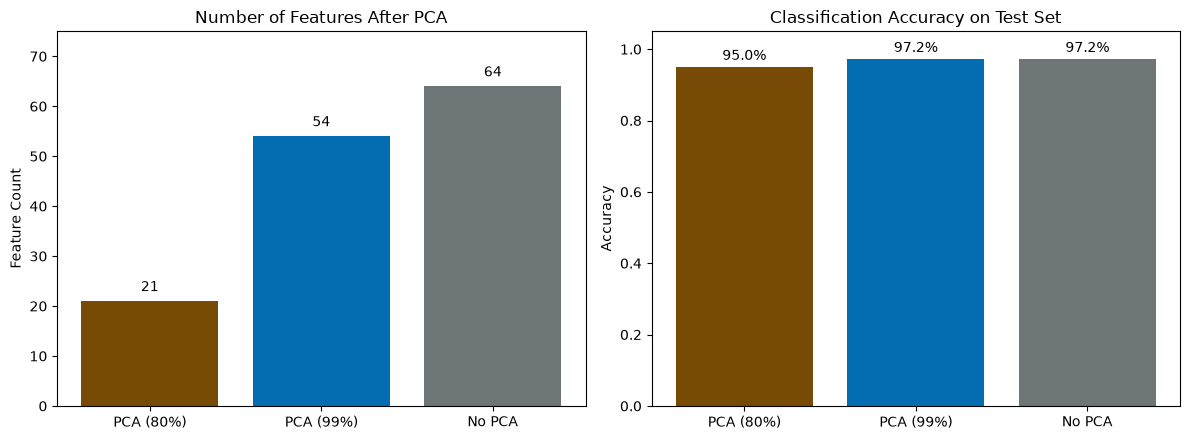

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

configs_plot = ["PCA (80%)", "PCA (99%)", "No PCA"]
feats = df_results["Number of Features"].tolist()
accs = df_results["Test Accuracy"].tolist()

# Colors: Orange, Blue, Gray
colors = ["#774B05", "#046CB1", "#6E7576"]

# Chart 1: Number of Features
axes[0].bar(configs_plot, feats, color=colors)
axes[0].set_title("Number of Features After PCA")
axes[0].set_ylabel("Feature Count")
axes[0].set_ylim(0, 75)

for i, v in enumerate(feats):
    axes[0].text(i, v + 2, str(v), ha="center")

# Chart 2: Classification Accuracy
axes[1].bar(configs_plot, accs, color=colors)
axes[1].set_title("Classification Accuracy on Test Set")
axes[1].set_ylabel("Accuracy")
axes[1].set_ylim(0, 1.05)

for i, v in enumerate(accs):
    axes[1].text(i, v + 0.02, f"{v:.1%}", ha="center")

plt.tight_layout()
plt.show()

## Final Answer

**How do the number of features and the accuracy change when trying `PCA(n_components=0.80)` and `PCA(n_components=0.99)`?**

### 1. Number of Features

- **Raw Data / No PCA:** 64 features.
- **PCA (`n_components=0.80`):** Reduces the dimensionality to 21 features, a 67.2% reduction, while retaining at least 80% of the variance.
- **PCA (`n_components=0.99`):** Retains 54 features, a 15.6% reduction, while retaining at least 99% of the variance.

### 2. Test Accuracy

- **PCA (80%, 21 features):** Achieves 95.00% test accuracy, slightly lower than the baseline, while using approximately one-third of the original features.
- **PCA (99%, 54 features):** Achieves 97.22% test accuracy, matching the baseline accuracy of 97.22% obtained without PCA.

### 3. Conclusion / Key Takeaway

Using `PCA(n_components=0.99)` preserves the baseline test accuracy while reducing the number of features from 64 to 54. Meanwhile, `PCA(n_components=0.80)` reduces the feature count more substantially, from 64 to 21, but test accuracy decreases from 97.22% to 95.00%.

These results illustrate the trade-off between dimensionality reduction and classification accuracy.